# CLAM-TR v5: Comprehensive Category-by-Category Ablation Study

## Goals:
1. Test improvements **CATEGORY BY CATEGORY**
2. Find the **BEST option** in each category
3. **Combine ALL helpful changes** from all categories
4. Run **5-Fold CV** on baseline and best combination
5. Compare with statistical significance

## Categories (15 total):
| # | Category | Description |
|---|----------|-------------|
| 1 | Class Imbalance | How to handle imbalanced classes |
| 2 | K Value | Number of top patches to select |
| 3 | Optimizer | Which optimizer to use |
| 4 | LR Schedule | Learning rate scheduling strategy |
| 5 | Weight Decay | Regularization strength |
| 6 | Feature Augmentation | Data augmentation at feature level |
| 7 | Label Smoothing | Label smoothing amount |
| 8 | Attention Temperature | Sharpness of attention |
| 9 | Gamma Values | Spatial retention decay rates |
| 10 | Gradient Clipping | Gradient clipping for stability |
| 11 | Hidden Dimension | Model capacity |
| 12 | Number of Heads | Spatial retention heads |
| 13 | Dropout | Dropout rate |
| 14 | Ordinal Loss | Ordinal loss for grade ordering |
| 15 | RetNet Architecture | Multiple RetNet design variations |

**CRITICAL:** This notebook reuses existing UNI features - NO re-extraction needed!

**Estimated Time:** ~100 hours total (Categories 1-14: ~80h, Category 15: ~20h)

---
## Section 1: Setup & Installation

In [1]:
!pip install -q scikit-learn pandas matplotlib seaborn tqdm

In [2]:
import os
import json
import copy
import random
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score, confusion_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

print('All imports successful!')

Mounted at /content/drive
All imports successful!


---
## Section 2: Configuration

In [3]:
# ============================================================================
# CONFIGURATION
# ============================================================================

CONFIG = {
    # Paths (READ-ONLY)
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/',
    'original_checkpoints': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',

    # Paths (WRITE - separate folder)
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/v5_category_ablation/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v5_category_ablation/',

    # Baseline parameters (from working model)
    'feature_dim': 1024,
    'hidden_dim': 512,
    'n_classes': 6,
    'patch_size': 256,
    'num_heads': 8,
    'gamma_values': [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99],
    'K': 128,
    'dropout': 0.25,
    'epochs': 50,
    'lr': 1e-4,
    'weight_decay': 1e-5,
    'label_smoothing': 0.1,

    # Early stopping
    'early_stopping_patience': 10,
    'seed': 42,
    'n_folds': 5,
}

# Set seeds
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
torch.cuda.manual_seed_all(CONFIG['seed'])
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

# Create directories
os.makedirs(CONFIG['checkpoints_dir'], exist_ok=True)
os.makedirs(CONFIG['results_dir'], exist_ok=True)
os.makedirs(os.path.join(CONFIG['results_dir'], 'models'), exist_ok=True)
os.makedirs(os.path.join(CONFIG['results_dir'], 'visualizations'), exist_ok=True)

print(f'\nCheckpoints: {CONFIG["checkpoints_dir"]}')
print(f'Results: {CONFIG["results_dir"]}')

Device: cuda
GPU: NVIDIA L4

Checkpoints: /content/drive/MyDrive/CLAM_TR_Checkpoints/v5_category_ablation/
Results: /content/drive/MyDrive/CLAM_TR_Results/v5_category_ablation/


---
## Section 3: Define All Categories

In [4]:
# ============================================================================
# ALL CATEGORIES TO TEST
# ============================================================================
# Each category tests ONE type of change
# We find the BEST option in each category
# Then combine ALL best options at the end
# ============================================================================

CATEGORIES = {

    # ========================================================================
    # CATEGORY 1: CLASS IMBALANCE HANDLING
    # ========================================================================
    'cat1_class_imbalance': {
        'description': 'How to handle class imbalance (G1, G2 are hard)',
        'experiments': {
            'baseline': {
                'name': 'No handling (baseline)',
            },
            'class_weights_v1': {
                'name': 'Class weights [1, 2, 2.5, 1.5, 1.5, 1]',
                'use_class_weights': True,
                'class_weights': [1.0, 2.0, 2.5, 1.5, 1.5, 1.0],
            },
            'class_weights_v2': {
                'name': 'Class weights [1, 2.5, 3, 2, 1.5, 1]',
                'use_class_weights': True,
                'class_weights': [1.0, 2.5, 3.0, 2.0, 1.5, 1.0],
            },
            'weighted_sampler': {
                'name': 'Weighted random sampling',
                'use_weighted_sampler': True,
            },
            'focal_loss_g1': {
                'name': 'Focal loss (gamma=1)',
                'use_focal_loss': True,
                'focal_gamma': 1.0,
            },
            'focal_loss_g2': {
                'name': 'Focal loss (gamma=2)',
                'use_focal_loss': True,
                'focal_gamma': 2.0,
            },
            'focal_loss_g3': {
                'name': 'Focal loss (gamma=3)',
                'use_focal_loss': True,
                'focal_gamma': 3.0,
            },
        }
    },

    # ========================================================================
    # CATEGORY 2: K VALUE (Top-K patches)
    # ========================================================================
    'cat2_k_value': {
        'description': 'How many top patches to select',
        'experiments': {
            'K128': {
                'name': 'K=128 (baseline)',
                'K': 128,
            },
            'K32': {
                'name': 'K=32',
                'K': 32,
            },
            'K64': {
                'name': 'K=64',
                'K': 64,
            },
            'K96': {
                'name': 'K=96',
                'K': 96,
            },
            'K160': {
                'name': 'K=160',
                'K': 160,
            },
            'K192': {
                'name': 'K=192',
                'K': 192,
            },
        }
    },

    # ========================================================================
    # CATEGORY 3: OPTIMIZER
    # ========================================================================
    'cat3_optimizer': {
        'description': 'Which optimizer to use',
        'experiments': {
            'adam': {
                'name': 'Adam (baseline)',
                'optimizer': 'adam',
            },
            'adamw': {
                'name': 'AdamW',
                'optimizer': 'adamw',
            },
            'sgd': {
                'name': 'SGD (momentum=0.9)',
                'optimizer': 'sgd',
                'momentum': 0.9,
            },
            'sgd_nesterov': {
                'name': 'SGD (nesterov)',
                'optimizer': 'sgd',
                'momentum': 0.9,
                'nesterov': True,
            },
        }
    },

    # ========================================================================
    # CATEGORY 4: LEARNING RATE SCHEDULE
    # ========================================================================
    'cat4_lr_schedule': {
        'description': 'Learning rate scheduling strategy',
        'experiments': {
            'cosine': {
                'name': 'CosineAnnealing (baseline)',
                'scheduler': 'cosine',
            },
            'warmup_3': {
                'name': 'Warmup 3 epochs + Cosine',
                'scheduler': 'cosine',
                'use_warmup': True,
                'warmup_epochs': 3,
            },
            'warmup_5': {
                'name': 'Warmup 5 epochs + Cosine',
                'scheduler': 'cosine',
                'use_warmup': True,
                'warmup_epochs': 5,
            },
            'plateau': {
                'name': 'ReduceLROnPlateau',
                'scheduler': 'plateau',
                'plateau_patience': 5,
                'plateau_factor': 0.5,
            },
            'step': {
                'name': 'StepLR (step=15)',
                'scheduler': 'step',
                'step_size': 15,
                'step_gamma': 0.5,
            },
        }
    },

    # ========================================================================
    # CATEGORY 5: WEIGHT DECAY
    # ========================================================================
    'cat5_weight_decay': {
        'description': 'Regularization strength',
        'experiments': {
            'wd_1e5': {
                'name': 'weight_decay=1e-5 (baseline)',
                'weight_decay': 1e-5,
            },
            'wd_5e5': {
                'name': 'weight_decay=5e-5',
                'weight_decay': 5e-5,
            },
            'wd_1e4': {
                'name': 'weight_decay=1e-4',
                'weight_decay': 1e-4,
            },
            'wd_5e4': {
                'name': 'weight_decay=5e-4',
                'weight_decay': 5e-4,
            },
            'wd_1e3': {
                'name': 'weight_decay=1e-3',
                'weight_decay': 1e-3,
            },
        }
    },

    # ========================================================================
    # CATEGORY 6: FEATURE AUGMENTATION
    # ========================================================================
    'cat6_feature_augmentation': {
        'description': 'Data augmentation at feature level',
        'experiments': {
            'no_aug': {
                'name': 'No augmentation (baseline)',
            },
            'noise_001': {
                'name': 'Gaussian noise (std=0.01)',
                'use_feature_noise': True,
                'noise_std': 0.01,
            },
            'noise_002': {
                'name': 'Gaussian noise (std=0.02)',
                'use_feature_noise': True,
                'noise_std': 0.02,
            },
            'noise_005': {
                'name': 'Gaussian noise (std=0.05)',
                'use_feature_noise': True,
                'noise_std': 0.05,
            },
            'feat_dropout_01': {
                'name': 'Feature dropout (p=0.1)',
                'use_feature_dropout': True,
                'feature_dropout': 0.1,
            },
            'feat_dropout_02': {
                'name': 'Feature dropout (p=0.2)',
                'use_feature_dropout': True,
                'feature_dropout': 0.2,
            },
            'patch_dropout_01': {
                'name': 'Patch dropout (p=0.1)',
                'use_patch_dropout': True,
                'patch_dropout': 0.1,
            },
            'patch_dropout_02': {
                'name': 'Patch dropout (p=0.2)',
                'use_patch_dropout': True,
                'patch_dropout': 0.2,
            },
        }
    },

    # ========================================================================
    # CATEGORY 7: LABEL SMOOTHING
    # ========================================================================
    'cat7_label_smoothing': {
        'description': 'Label smoothing amount',
        'experiments': {
            'smooth_0': {
                'name': 'No smoothing',
                'label_smoothing': 0.0,
            },
            'smooth_005': {
                'name': 'Smoothing 0.05',
                'label_smoothing': 0.05,
            },
            'smooth_01': {
                'name': 'Smoothing 0.1 (baseline)',
                'label_smoothing': 0.1,
            },
            'smooth_015': {
                'name': 'Smoothing 0.15',
                'label_smoothing': 0.15,
            },
            'smooth_02': {
                'name': 'Smoothing 0.2',
                'label_smoothing': 0.2,
            },
        }
    },

    # ========================================================================
    # CATEGORY 8: ATTENTION TEMPERATURE
    # ========================================================================
    'cat8_attention_temperature': {
        'description': 'Sharpness of attention distribution',
        'experiments': {
            'temp_1': {
                'name': 'Temperature 1.0 (baseline)',
                'attention_temperature': 1.0,
            },
            'temp_05': {
                'name': 'Temperature 0.5 (sharper)',
                'attention_temperature': 0.5,
            },
            'temp_07': {
                'name': 'Temperature 0.7',
                'attention_temperature': 0.7,
            },
            'temp_15': {
                'name': 'Temperature 1.5',
                'attention_temperature': 1.5,
            },
            'temp_2': {
                'name': 'Temperature 2.0 (softer)',
                'attention_temperature': 2.0,
            },
        }
    },

    # ========================================================================
    # CATEGORY 9: GAMMA VALUES (Spatial Decay)
    # ========================================================================
    'cat9_gamma_values': {
        'description': 'Spatial retention decay rates',
        'experiments': {
            'gamma_default': {
                'name': 'Default [0.80-0.99]',
                'gamma_values': [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99],
            },
            'gamma_low': {
                'name': 'Lower [0.70-0.95] (faster decay)',
                'gamma_values': [0.70, 0.75, 0.80, 0.84, 0.88, 0.91, 0.93, 0.95],
            },
            'gamma_high': {
                'name': 'Higher [0.88-0.995] (slower decay)',
                'gamma_values': [0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995],
            },
            'gamma_narrow': {
                'name': 'Narrow [0.90-0.98]',
                'gamma_values': [0.90, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.98],
            },
        }
    },

    # ========================================================================
    # CATEGORY 10: GRADIENT CLIPPING
    # ========================================================================
    'cat10_gradient_clipping': {
        'description': 'Gradient clipping for stability',
        'experiments': {
            'no_clip': {
                'name': 'No clipping (baseline)',
                'grad_clip': None,
            },
            'clip_05': {
                'name': 'Clip max_norm=0.5',
                'grad_clip': 0.5,
            },
            'clip_1': {
                'name': 'Clip max_norm=1.0',
                'grad_clip': 1.0,
            },
            'clip_2': {
                'name': 'Clip max_norm=2.0',
                'grad_clip': 2.0,
            },
            'clip_5': {
                'name': 'Clip max_norm=5.0',
                'grad_clip': 5.0,
            },
        }
    },

    # ========================================================================
    # CATEGORY 11: HIDDEN DIMENSION
    # ========================================================================
    'cat11_hidden_dim': {
        'description': 'Model capacity (hidden layer size)',
        'experiments': {
            'hidden_256': {
                'name': 'hidden_dim=256',
                'hidden_dim': 256,
            },
            'hidden_384': {
                'name': 'hidden_dim=384',
                'hidden_dim': 384,
            },
            'hidden_512': {
                'name': 'hidden_dim=512 (baseline)',
                'hidden_dim': 512,
            },
            'hidden_768': {
                'name': 'hidden_dim=768',
                'hidden_dim': 768,
            },
        }
    },

    # ========================================================================
    # CATEGORY 12: NUMBER OF HEADS
    # ========================================================================
    'cat12_num_heads': {
        'description': 'Number of spatial retention heads',
        'experiments': {
            'heads_4': {
                'name': '4 heads',
                'num_heads': 4,
            },
            'heads_8': {
                'name': '8 heads (baseline)',
                'num_heads': 8,
            },
            'heads_12': {
                'name': '12 heads',
                'num_heads': 12,
            },
            'heads_16': {
                'name': '16 heads',
                'num_heads': 16,
            },
        }
    },

    # ========================================================================
    # CATEGORY 13: DROPOUT
    # ========================================================================
    'cat13_dropout': {
        'description': 'Dropout rate',
        'experiments': {
            'dropout_015': {
                'name': 'Dropout 0.15',
                'dropout': 0.15,
            },
            'dropout_02': {
                'name': 'Dropout 0.2',
                'dropout': 0.2,
            },
            'dropout_025': {
                'name': 'Dropout 0.25 (baseline)',
                'dropout': 0.25,
            },
            'dropout_03': {
                'name': 'Dropout 0.3',
                'dropout': 0.3,
            },
            'dropout_035': {
                'name': 'Dropout 0.35',
                'dropout': 0.35,
            },
            'dropout_04': {
                'name': 'Dropout 0.4',
                'dropout': 0.4,
            },
        }
    },

    # ========================================================================
    # CATEGORY 14: ORDINAL LOSS
    # ========================================================================
    'cat14_ordinal_loss': {
        'description': 'Ordinal loss for grade ordering',
        'experiments': {
            'no_ordinal': {
                'name': 'No ordinal (baseline)',
                'use_ordinal_loss': False,
            },
            'ordinal_01': {
                'name': 'Ordinal weight=0.1',
                'use_ordinal_loss': True,
                'ordinal_weight': 0.1,
            },
            'ordinal_02': {
                'name': 'Ordinal weight=0.2',
                'use_ordinal_loss': True,
                'ordinal_weight': 0.2,
            },
            'ordinal_03': {
                'name': 'Ordinal weight=0.3',
                'use_ordinal_loss': True,
                'ordinal_weight': 0.3,
            },
            'ordinal_04': {
                'name': 'Ordinal weight=0.4',
                'use_ordinal_loss': True,
                'ordinal_weight': 0.4,
            },
            'ordinal_05': {
                'name': 'Ordinal weight=0.5',
                'use_ordinal_loss': True,
                'ordinal_weight': 0.5,
            },
        }
    },
}

print(f'Total categories: {len(CATEGORIES)}')
total_exp = sum(len(cat['experiments']) for cat in CATEGORIES.values())
print(f'Total experiments: {total_exp}')
print('\nCategories:')
for i, (name, cat) in enumerate(CATEGORIES.items(), 1):
    print(f'  {i:2d}. {name}: {len(cat["experiments"])} experiments')

Total categories: 14
Total experiments: 74

Categories:
   1. cat1_class_imbalance: 7 experiments
   2. cat2_k_value: 6 experiments
   3. cat3_optimizer: 4 experiments
   4. cat4_lr_schedule: 5 experiments
   5. cat5_weight_decay: 5 experiments
   6. cat6_feature_augmentation: 8 experiments
   7. cat7_label_smoothing: 5 experiments
   8. cat8_attention_temperature: 5 experiments
   9. cat9_gamma_values: 4 experiments
  10. cat10_gradient_clipping: 5 experiments
  11. cat11_hidden_dim: 4 experiments
  12. cat12_num_heads: 4 experiments
  13. cat13_dropout: 6 experiments
  14. cat14_ordinal_loss: 6 experiments


---
## Section 4: Core Classes (Dataset, Model, Loss)

In [5]:
# ============================================================================
# EARLY STOPPING
# ============================================================================

class EarlyStopping:
    """Stop training when validation metric stops improving."""
    def __init__(self, patience=10, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_score = None
        self.should_stop = False

    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
        elif score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
                return True
        return False

    def reset(self):
        self.counter = 0
        self.best_score = None
        self.should_stop = False

print('EarlyStopping defined!')

EarlyStopping defined!


In [6]:
# ============================================================================
# DATASET
# ============================================================================

class PANDAFeatureDataset(Dataset):
    """Dataset that loads pre-extracted features."""
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        data = torch.load(
            os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'),
            map_location='cpu'
        )
        return data['features'], data['coordinates'], self.labels[idx], self.slide_ids[idx]


def collate_fn(batch):
    """Custom collate for single-sample batches."""
    return batch[0][0], batch[0][1], batch[0][2], batch[0][3]


print('Dataset classes defined!')

Dataset classes defined!


In [7]:
# ============================================================================
# SPATIAL RETENTION HEAD
# ============================================================================

class SpatialRetentionHead(nn.Module):
    """Single head of spatial retention."""
    def __init__(self, head_dim, gamma, patch_size):
        super().__init__()
        self.gamma = gamma
        self.patch_size = patch_size
        self.head_dim = head_dim

        self.W_Q = nn.Linear(head_dim, head_dim, bias=False)
        self.W_K = nn.Linear(head_dim, head_dim, bias=False)
        self.W_V = nn.Linear(head_dim, head_dim, bias=False)

    def forward(self, x, coords):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)

        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)
        normalized = distances / (distances.max() + 1e-6)

        D = self.gamma ** normalized
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.head_dim ** 0.5)
        scores = scores * D
        attn = F.softmax(scores, dim=-1)

        return torch.matmul(attn, V)


# ============================================================================
# FLEXIBLE CLAM-TR MODEL
# ============================================================================

class CLAM_TR_Flexible(nn.Module):
    """
    Flexible CLAM-TR model that supports all configuration options.
    """
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6,
                 dropout=0.25, K=128, num_heads=8, gamma_values=None,
                 patch_size=256, attention_temperature=1.0):
        super().__init__()
        self.K = K
        self.attention_temperature = attention_temperature
        self.num_heads = num_heads
        self.hidden_dim = hidden_dim

        # Calculate head_dim - ensure it divides evenly
        self.head_dim = hidden_dim // num_heads

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Gated attention
        self.attention_a = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Sigmoid(),
            nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim // 2, 1)

        # Spatial retention
        if gamma_values is None:
            gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]

        # Adjust gamma_values to match num_heads
        if len(gamma_values) != num_heads:
            gamma_values = np.linspace(gamma_values[0], gamma_values[-1], num_heads).tolist()

        # Project hidden_dim to head_dim for each head
        self.pre_retention_proj = nn.Linear(hidden_dim, self.head_dim * num_heads)

        self.heads = nn.ModuleList([
            SpatialRetentionHead(self.head_dim, gamma_values[i], patch_size)
            for i in range(num_heads)
        ])

        # Project concatenated heads back to hidden_dim
        self.retention_proj = nn.Linear(self.head_dim * num_heads, hidden_dim)

        # Classifier
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords):
        h = self.feature_transform(x)

        # Gated attention with temperature
        a = self.attention_a(h)
        b = self.attention_b(h)
        A = self.attention_c(a * b).squeeze(-1) / self.attention_temperature
        A_softmax = F.softmax(A, dim=0)

        # Top-K selection
        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices

        h_topk = h[topk_indices]
        coords_topk = coords[topk_indices]
        A_topk = A_softmax[topk_indices]

        # CLAM aggregation
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)

        # Spatial retention
        # Project to head dimensions
        h_proj = self.pre_retention_proj(h_topk)  # [K, head_dim * num_heads]

        # Split into heads and process
        retention_outputs = []
        for i, head in enumerate(self.heads):
            head_input = h_proj[:, i*self.head_dim:(i+1)*self.head_dim]  # [K, head_dim]
            head_output = head(head_input, coords_topk)  # [K, head_dim]
            retention_outputs.append(head_output)

        retention_concat = torch.cat(retention_outputs, dim=-1)  # [K, head_dim * num_heads]
        M_retention = torch.mean(self.retention_proj(retention_concat), dim=0)  # [hidden_dim]

        # Combine
        M = M_clam + M_retention

        return self.classifier(M)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print('CLAM_TR_Flexible model defined (fixed for any num_heads)!')

CLAM_TR_Flexible model defined (fixed for any num_heads)!


In [8]:
# ============================================================================
# FLEXIBLE LOSS
# ============================================================================

class FlexibleLoss(nn.Module):
    """
    Loss function that supports:
    - Label smoothing
    - Focal loss
    - Class weights
    - Ordinal loss (penalizes predictions far from true grade)
    """
    def __init__(self, n_classes=6, smoothing=0.1,
                 use_focal=False, focal_gamma=2.0,
                 class_weights=None,
                 use_ordinal=False, ordinal_weight=0.3):
        super().__init__()
        self.n_classes = n_classes
        self.smoothing = smoothing
        self.use_focal = use_focal
        self.focal_gamma = focal_gamma
        self.use_ordinal = use_ordinal
        self.ordinal_weight = ordinal_weight

        if class_weights is not None:
            self.register_buffer('class_weights', torch.tensor(class_weights, dtype=torch.float))
        else:
            self.class_weights = None

    def forward(self, pred, target):
        if pred.dim() == 1:
            pred = pred.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        # Label smoothing CE
        confidence = 1.0 - self.smoothing
        smooth_label = self.smoothing / (self.n_classes - 1)
        one_hot = torch.zeros_like(pred).scatter_(1, target.unsqueeze(1), 1)
        smooth_target = one_hot * confidence + (1 - one_hot) * smooth_label

        log_probs = F.log_softmax(pred, dim=1)
        ce_loss = -(smooth_target * log_probs).sum(dim=1)

        # Class weights
        if self.class_weights is not None:
            weights = self.class_weights[target]
            ce_loss = ce_loss * weights

        # Focal weighting
        if self.use_focal:
            probs = torch.exp(log_probs)
            pt = probs.gather(1, target.unsqueeze(1)).squeeze(1)
            focal_weight = (1 - pt) ** self.focal_gamma
            ce_loss = ce_loss * focal_weight

        total_loss = ce_loss.mean()

        # Ordinal loss: penalize predictions far from true grade
        if self.use_ordinal:
            probs = F.softmax(pred, dim=1)
            # Create class indices [0, 1, 2, 3, 4, 5]
            class_indices = torch.arange(self.n_classes, device=pred.device, dtype=torch.float)
            # Expected prediction (weighted average of class indices)
            expected_pred = (probs * class_indices.unsqueeze(0)).sum(dim=1)
            # Ordinal penalty: squared distance from true class
            ordinal_penalty = (expected_pred - target.float()) ** 2
            # Normalize by max possible distance squared
            max_dist_sq = (self.n_classes - 1) ** 2
            ordinal_loss = ordinal_penalty.mean() / max_dist_sq

            total_loss = total_loss + self.ordinal_weight * ordinal_loss

        return total_loss


print('FlexibleLoss defined (with ordinal loss support)!')

FlexibleLoss defined (with ordinal loss support)!


---
## Section 5: Training Function

In [9]:
def train_single_experiment(exp_config, train_loader, val_loader, device, verbose=False):
    """
    Train a single experiment and return metrics.

    Args:
        exp_config: Dictionary with experiment configuration
        train_loader: Training data loader
        val_loader: Validation data loader
        device: Device to train on
        verbose: Print progress

    Returns:
        Dictionary with metrics (qwk, accuracy, macro_f1, best_epoch)
    """

    # Get all parameters with defaults
    hidden_dim = exp_config.get('hidden_dim', CONFIG['hidden_dim'])
    num_heads = exp_config.get('num_heads', CONFIG['num_heads'])
    gamma_values = exp_config.get('gamma_values', CONFIG['gamma_values'])
    K = exp_config.get('K', CONFIG['K'])
    dropout = exp_config.get('dropout', CONFIG['dropout'])
    attention_temp = exp_config.get('attention_temperature', 1.0)

    # Create model
    model = CLAM_TR_Flexible(
        input_dim=CONFIG['feature_dim'],
        hidden_dim=hidden_dim,
        n_classes=CONFIG['n_classes'],
        dropout=dropout,
        K=K,
        num_heads=num_heads,
        gamma_values=gamma_values,
        patch_size=CONFIG['patch_size'],
        attention_temperature=attention_temp
    ).to(device)

    # Create loss (with ordinal loss support) - MOVE TO DEVICE for class_weights buffer
    criterion = FlexibleLoss(
        n_classes=CONFIG['n_classes'],
        smoothing=exp_config.get('label_smoothing', CONFIG['label_smoothing']),
        use_focal=exp_config.get('use_focal_loss', False),
        focal_gamma=exp_config.get('focal_gamma', 2.0),
        class_weights=exp_config.get('class_weights') if exp_config.get('use_class_weights', False) else None,
        use_ordinal=exp_config.get('use_ordinal_loss', False),
        ordinal_weight=exp_config.get('ordinal_weight', 0.3)
    ).to(device)  # Move criterion to device for class_weights buffer

    # Create optimizer
    lr = exp_config.get('lr', CONFIG['lr'])
    weight_decay = exp_config.get('weight_decay', CONFIG['weight_decay'])
    optimizer_type = exp_config.get('optimizer', 'adam')

    if optimizer_type == 'adam':
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_type == 'adamw':
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_type == 'sgd':
        momentum = exp_config.get('momentum', 0.9)
        nesterov = exp_config.get('nesterov', False)
        optimizer = torch.optim.SGD(
            model.parameters(), lr=lr, weight_decay=weight_decay,
            momentum=momentum, nesterov=nesterov
        )
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # Create scheduler
    epochs = exp_config.get('epochs', CONFIG['epochs'])
    scheduler_type = exp_config.get('scheduler', 'cosine')

    if scheduler_type == 'cosine':
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    elif scheduler_type == 'plateau':
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            patience=exp_config.get('plateau_patience', 5),
            factor=exp_config.get('plateau_factor', 0.5)
        )
    elif scheduler_type == 'step':
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer,
            step_size=exp_config.get('step_size', 15),
            gamma=exp_config.get('step_gamma', 0.5)
        )
    else:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    # Training settings
    use_warmup = exp_config.get('use_warmup', False)
    warmup_epochs = exp_config.get('warmup_epochs', 5)
    grad_clip = exp_config.get('grad_clip', None)
    use_feature_noise = exp_config.get('use_feature_noise', False)
    noise_std = exp_config.get('noise_std', 0.01)
    use_feature_dropout = exp_config.get('use_feature_dropout', False)
    feature_dropout = exp_config.get('feature_dropout', 0.1)
    use_patch_dropout = exp_config.get('use_patch_dropout', False)
    patch_dropout = exp_config.get('patch_dropout', 0.1)

    early_stopping = EarlyStopping(patience=CONFIG['early_stopping_patience'])
    best_qwk = -1
    best_model_state = None
    best_epoch = 0

    for epoch in range(epochs):
        model.train()

        # Warmup LR
        if use_warmup and epoch < warmup_epochs:
            warmup_lr = lr * (epoch + 1) / warmup_epochs
            for param_group in optimizer.param_groups:
                param_group['lr'] = warmup_lr

        for features, coords, label, _ in train_loader:
            features, coords = features.to(device), coords.to(device)
            label = torch.tensor(label).to(device)

            # Feature augmentation
            if use_feature_noise:
                features = features + torch.randn_like(features) * noise_std
            if use_feature_dropout:
                features = F.dropout(features, p=feature_dropout, training=True)
            if use_patch_dropout and features.size(0) > 20:
                n_keep = int(features.size(0) * (1 - patch_dropout))
                indices = torch.randperm(features.size(0))[:n_keep]
                features = features[indices]
                coords = coords[indices]

            optimizer.zero_grad()
            logits = model(features, coords)
            loss = criterion(logits, label)
            loss.backward()

            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)

            optimizer.step()

        # Scheduler step
        if scheduler_type in ['cosine', 'step']:
            if not use_warmup or epoch >= warmup_epochs:
                scheduler.step()

        # Validate
        model.eval()
        preds, labels = [], []
        with torch.no_grad():
            for features, coords, label, _ in val_loader:
                features, coords = features.to(device), coords.to(device)
                logits = model(features, coords)
                preds.append(logits.argmax().cpu().item())
                labels.append(label)

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')

        if scheduler_type == 'plateau':
            scheduler.step(qwk)

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            if verbose:
                acc = accuracy_score(labels, preds)
                print(f'    Epoch {epoch+1}: QWK={qwk:.4f}*, Acc={acc:.4f}')

        if early_stopping(qwk):
            if verbose:
                print(f'    Early stopping at epoch {epoch+1}')
            break

    # Final evaluation with best model
    model.load_state_dict(best_model_state)
    model.eval()

    preds, labels = [], []
    with torch.no_grad():
        for features, coords, label, _ in val_loader:
            features, coords = features.to(device), coords.to(device)
            logits = model(features, coords)
            preds.append(logits.argmax().cpu().item())
            labels.append(label)

    # Cleanup
    del model
    del criterion
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        'qwk': cohen_kappa_score(labels, preds, weights='quadratic'),
        'accuracy': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
        'best_epoch': best_epoch,
    }


print('train_single_experiment function defined!')

train_single_experiment function defined!


---
## Section 6: Category Runner

In [10]:
def run_category(category_name, category_data, train_loader, val_loader, train_df=None, features_dir=None):
    """
    Run all experiments in a single category.

    Args:
        category_name: Name of the category
        category_data: Dictionary with category description and experiments
        train_loader: Training data loader
        val_loader: Validation data loader
        train_df: Training dataframe (for weighted sampler)
        features_dir: Features directory (for weighted sampler)

    Returns:
        results: Dictionary with all experiment results
        best: Tuple of (best_exp_name, best_exp_data)
    """

    print(f'\n{"="*70}')
    print(f'CATEGORY: {category_name}')
    print(f'Description: {category_data["description"]}')
    print(f'Experiments: {len(category_data["experiments"])}')
    print(f'{"="*70}')

    results = {}

    for exp_name, exp_config in category_data['experiments'].items():
        print(f'\n  Running: {exp_config["name"]}...', end=' ', flush=True)

        # Handle weighted sampler specially
        if exp_config.get('use_weighted_sampler', False) and train_df is not None:
            class_sample_weights = {0: 1.0, 1: 2.0, 2: 2.5, 3: 1.5, 4: 1.5, 5: 1.0}
            sample_weights = [class_sample_weights[l] for l in train_df['isup_grade'].tolist()]
            sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

            train_ds = PANDAFeatureDataset(
                train_df['image_id'].tolist(),
                train_df['isup_grade'].tolist(),
                features_dir
            )
            current_train_loader = DataLoader(
                train_ds, batch_size=1, sampler=sampler, collate_fn=collate_fn
            )
        else:
            current_train_loader = train_loader

        metrics = train_single_experiment(exp_config, current_train_loader, val_loader, DEVICE)
        results[exp_name] = {
            'name': exp_config['name'],
            'config': exp_config,
            'metrics': metrics
        }

        print(f'QWK={metrics["qwk"]:.4f}, Acc={metrics["accuracy"]:.4f}')

    # Find best in category
    best_exp = max(results.items(), key=lambda x: x[1]['metrics']['qwk'])

    # Print category summary
    print(f'\n{"-"*70}')
    print(f'CATEGORY RESULTS: {category_name}')
    print(f'{"-"*70}')
    print(f'{"Experiment":<35} {"QWK":>10} {"Accuracy":>10} {"Epoch":>8}')
    print(f'{"-"*70}')

    for exp_name, data in sorted(results.items(), key=lambda x: x[1]['metrics']['qwk'], reverse=True):
        marker = ' *' if exp_name == best_exp[0] else ''
        print(f'{data["name"]:<35} {data["metrics"]["qwk"]:>10.4f} {data["metrics"]["accuracy"]:>10.4f} {data["metrics"]["best_epoch"]:>8}{marker}')

    print(f'{"-"*70}')
    print(f'BEST: {best_exp[1]["name"]} (QWK={best_exp[1]["metrics"]["qwk"]:.4f})')
    print(f'{"="*70}')

    return results, best_exp


print('run_category function defined!')

run_category function defined!


---
## Section 7: Run All Categories

In [11]:
def run_all_categories():
    """
    Run all categories and find best from each.

    Returns:
        all_results: Dictionary with results from all categories
        best_per_category: Dictionary with best experiment per category
    """

    print('='*70)
    print('STARTING CATEGORY-BY-CATEGORY ABLATION STUDY')
    print(f'Total categories: {len(CATEGORIES)}')
    print(f'Total experiments: {sum(len(c["experiments"]) for c in CATEGORIES.values())}')
    print('='*70)

    # Load data
    subset_csv = os.path.join(CONFIG['original_checkpoints'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['features_dir'], 'uni')

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    # Create single train/val split for consistent comparison
    train_df, val_df = train_test_split(
        df, test_size=0.2, stratify=df['isup_grade'], random_state=CONFIG['seed']
    )

    print(f'\nData: Train={len(train_df)}, Val={len(val_df)}')

    # Create default dataloaders
    train_ds = PANDAFeatureDataset(
        train_df['image_id'].tolist(),
        train_df['isup_grade'].tolist(),
        features_dir
    )
    val_ds = PANDAFeatureDataset(
        val_df['image_id'].tolist(),
        val_df['isup_grade'].tolist(),
        features_dir
    )

    train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

    # Store results
    all_results = {}
    best_per_category = {}

    # Check for existing results
    results_file = os.path.join(CONFIG['results_dir'], 'category_results.json')
    if os.path.exists(results_file):
        with open(results_file, 'r') as f:
            saved_data = json.load(f)
            all_results = saved_data.get('all_results', {})
            print(f'\nLoaded {len(all_results)} completed categories')

    # Run each category
    for cat_name, cat_data in CATEGORIES.items():
        # Skip if already completed
        if cat_name in all_results:
            print(f'\nSkipping {cat_name} (already completed)')
            # Reconstruct best_per_category
            cat_results = all_results[cat_name]
            best_exp = max(cat_results.items(), key=lambda x: x[1]['metrics']['qwk'])
            best_per_category[cat_name] = best_exp
            continue

        # Run category
        results, best = run_category(
            cat_name, cat_data, train_loader, val_loader,
            train_df, features_dir
        )

        all_results[cat_name] = results
        best_per_category[cat_name] = best

        # Save intermediate results
        save_data = {
            'all_results': all_results,
            'best_per_category': {
                k: {'name': v[0], 'qwk': v[1]['metrics']['qwk']}
                for k, v in best_per_category.items()
            },
            'timestamp': datetime.now().isoformat()
        }
        with open(results_file, 'w') as f:
            json.dump(save_data, f, indent=2, default=str)

        # Clear GPU memory
        torch.cuda.empty_cache()

    return all_results, best_per_category


print('run_all_categories function defined!')

run_all_categories function defined!


---
## Section 8: Summary & Best Combination

In [12]:
def create_best_combination(best_per_category, all_results):
    """
    Create best combination from all categories.

    Args:
        best_per_category: Dictionary with best experiment per category
        all_results: Dictionary with all experiment results

    Returns:
        best_combination: Dictionary with combined best settings
        helpful_changes: Dictionary with changes that helped
    """

    print('\n' + '='*70)
    print('SUMMARY: BEST FROM EACH CATEGORY')
    print('='*70)

    # Get baseline QWK (from first category, baseline experiment)
    first_cat = list(all_results.keys())[0]
    baseline_qwk = None
    for exp_name, exp_data in all_results[first_cat].items():
        if 'baseline' in exp_name.lower() or 'baseline' in exp_data['name'].lower():
            baseline_qwk = exp_data['metrics']['qwk']
            break

    if baseline_qwk is None:
        baseline_qwk = all_results[first_cat][list(all_results[first_cat].keys())[0]]['metrics']['qwk']

    print(f'\nReference Baseline QWK: {baseline_qwk:.4f}')

    print(f'\n{"Category":<35} {"Best Option":<30} {"QWK":>10} {"vs Baseline":>12}')
    print('-'*90)

    # Track which settings helped
    helpful_changes = {}

    for cat_name, (best_name, best_data) in best_per_category.items():
        qwk = best_data['metrics']['qwk']
        diff = qwk - baseline_qwk

        if diff > 0.005:
            marker = '+'
        elif diff < -0.005:
            marker = '-'
        else:
            marker = '~'

        print(f'{cat_name:<35} {best_data["name"]:<30} {qwk:>10.4f} {diff:>+12.4f} {marker}')

        # If this helped, save the config
        if diff > 0.003:  # Small threshold to include marginal improvements
            helpful_changes[cat_name] = best_data['config']

    print('='*90)
    print('+ = Improved (>0.5%), ~ = Similar, - = Worse')

    # Create combined config
    print('\n' + '='*70)
    print('CREATING BEST COMBINATION')
    print('='*70)

    best_combination = {}

    for cat_name, config in helpful_changes.items():
        print(f'  + Adding from {cat_name}: {config.get("name", "?")}', flush=True)
        # Merge config (excluding 'name')
        for key, value in config.items():
            if key != 'name':
                best_combination[key] = value

    if not helpful_changes:
        print('  No clear improvements found - using baseline')
        best_combination = {}

    print('='*70)

    return best_combination, helpful_changes


print('create_best_combination function defined!')

create_best_combination function defined!


---
## Section 9: 5-Fold Cross-Validation

In [13]:
def run_5fold_cv(exp_config, description=''):
    """
    Run 5-fold CV on a configuration.

    Args:
        exp_config: Dictionary with experiment configuration
        description: Description for logging

    Returns:
        cv_results: Dictionary with CV results
    """

    print(f'\n{"="*70}')
    print(f'5-FOLD CROSS-VALIDATION: {description}')
    print(f'{"="*70}')

    # Load data
    subset_csv = os.path.join(CONFIG['original_checkpoints'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['features_dir'], 'uni')

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    print(f'Total samples: {len(df)}')

    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True, random_state=CONFIG['seed'])

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        print(f'\n--- Fold {fold+1}/{CONFIG["n_folds"]} ---')

        train_df = df.iloc[train_idx]
        val_df = df.iloc[val_idx]

        train_ds = PANDAFeatureDataset(
            train_df['image_id'].tolist(),
            train_df['isup_grade'].tolist(),
            features_dir
        )
        val_ds = PANDAFeatureDataset(
            val_df['image_id'].tolist(),
            val_df['isup_grade'].tolist(),
            features_dir
        )

        # Handle weighted sampler if needed
        if exp_config.get('use_weighted_sampler', False):
            class_sample_weights = {0: 1.0, 1: 2.0, 2: 2.5, 3: 1.5, 4: 1.5, 5: 1.0}
            sample_weights = [class_sample_weights[l] for l in train_df['isup_grade'].tolist()]
            sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)
            train_loader = DataLoader(train_ds, batch_size=1, sampler=sampler, collate_fn=collate_fn)
        else:
            train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)

        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

        metrics = train_single_experiment(exp_config, train_loader, val_loader, DEVICE)
        fold_results.append(metrics)

        print(f'  Fold {fold+1}: QWK={metrics["qwk"]:.4f}, Acc={metrics["accuracy"]:.4f}')

    # Compute stats
    qwk_scores = [r['qwk'] for r in fold_results]
    acc_scores = [r['accuracy'] for r in fold_results]
    f1_scores = [r['macro_f1'] for r in fold_results]

    cv_results = {
        'description': description,
        'config': exp_config,
        'fold_results': fold_results,
        'qwk_scores': qwk_scores,
        'acc_scores': acc_scores,
        'mean_qwk': float(np.mean(qwk_scores)),
        'std_qwk': float(np.std(qwk_scores)),
        'mean_accuracy': float(np.mean(acc_scores)),
        'std_accuracy': float(np.std(acc_scores)),
        'mean_f1': float(np.mean(f1_scores)),
        'std_f1': float(np.std(f1_scores)),
    }

    print(f'\n{"="*70}')
    print(f'5-FOLD CV RESULTS: {description}')
    print(f'{"="*70}')
    print(f'  QWK:      {cv_results["mean_qwk"]:.4f} +/- {cv_results["std_qwk"]:.4f}')
    print(f'  Accuracy: {cv_results["mean_accuracy"]:.4f} +/- {cv_results["std_accuracy"]:.4f}')
    print(f'  Macro F1: {cv_results["mean_f1"]:.4f} +/- {cv_results["std_f1"]:.4f}')
    print(f'{"="*70}')

    return cv_results


print('run_5fold_cv function defined!')

run_5fold_cv function defined!


---
## Section 10: Visualization

In [14]:
def plot_category_summary(all_results, best_per_category):
    """Plot summary of all categories."""

    # Get baseline QWK
    first_cat = list(all_results.keys())[0]
    baseline_qwk = None
    for exp_name, exp_data in all_results[first_cat].items():
        if 'baseline' in exp_name.lower():
            baseline_qwk = exp_data['metrics']['qwk']
            break
    if baseline_qwk is None:
        baseline_qwk = 0.83

    # Prepare data
    categories = list(best_per_category.keys())
    best_qwk = [best_per_category[c][1]['metrics']['qwk'] for c in categories]
    improvements = [q - baseline_qwk for q in best_qwk]

    # Colors
    colors = ['green' if i > 0.005 else ('red' if i < -0.005 else 'gray') for i in improvements]

    # Plot
    fig, ax = plt.subplots(figsize=(14, 8))

    y_pos = np.arange(len(categories))
    ax.barh(y_pos, best_qwk, color=colors, alpha=0.7)
    ax.axvline(x=baseline_qwk, color='black', linestyle='--', linewidth=2, label=f'Baseline ({baseline_qwk:.4f})')

    ax.set_yticks(y_pos)
    ax.set_yticklabels([c.replace('_', ' ').title() for c in categories])
    ax.set_xlabel('Best QWK in Category')
    ax.set_title('Category-by-Category Ablation Study Results')
    ax.legend()

    # Add value labels
    for i, (v, imp) in enumerate(zip(best_qwk, improvements)):
        ax.text(v + 0.002, i, f'{v:.4f} ({imp:+.4f})', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(
        os.path.join(CONFIG['results_dir'], 'visualizations', 'category_summary.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.show()


def plot_cv_comparison(cv_baseline, cv_best):
    """Plot CV comparison."""

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(3)
    width = 0.35

    baseline_means = [cv_baseline['mean_qwk'], cv_baseline['mean_accuracy'], cv_baseline['mean_f1']]
    baseline_stds = [cv_baseline['std_qwk'], cv_baseline['std_accuracy'], cv_baseline['std_f1']]

    best_means = [cv_best['mean_qwk'], cv_best['mean_accuracy'], cv_best['mean_f1']]
    best_stds = [cv_best['std_qwk'], cv_best['std_accuracy'], cv_best['std_f1']]

    bars1 = ax.bar(x - width/2, baseline_means, width, yerr=baseline_stds,
                   label='Baseline', capsize=5, color='steelblue')
    bars2 = ax.bar(x + width/2, best_means, width, yerr=best_stds,
                   label='Best Combination', capsize=5, color='forestgreen')

    ax.set_ylabel('Score')
    ax.set_title('5-Fold Cross-Validation: Baseline vs Best Combination')
    ax.set_xticks(x)
    ax.set_xticklabels(['QWK', 'Accuracy', 'Macro F1'])
    ax.legend()
    ax.set_ylim(0, 1)

    plt.tight_layout()
    plt.savefig(
        os.path.join(CONFIG['results_dir'], 'visualizations', 'cv_comparison.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.show()


print('Visualization functions defined!')

Visualization functions defined!


---
## Section 11: Verify Features

In [15]:
# ============================================================================
# VERIFY FEATURES BEFORE RUNNING
# ============================================================================

print('='*60)
print('VERIFYING UNI FEATURES')
print('='*60)

uni_dir = os.path.join(CONFIG['features_dir'], 'uni')

if os.path.exists(uni_dir):
    n_features = len([f for f in os.listdir(uni_dir) if f.endswith('.pt')])
    print(f'UNI features found: {n_features}/600')

    if n_features >= 600:
        print('\nREADY TO RUN ABLATION STUDY!')

        # Check sample
        sample = [f for f in os.listdir(uni_dir) if f.endswith('.pt')][0]
        data = torch.load(os.path.join(uni_dir, sample), map_location='cpu')
        print(f'\nSample: {sample}')
        print(f'  Features: {data["features"].shape}')
        print(f'  Coords: {data["coordinates"].shape}')
    else:
        print(f'\nWARNING: Only {n_features}/600 features found')
else:
    print(f'ERROR: UNI features not found at {uni_dir}')

print('='*60)

VERIFYING UNI FEATURES
UNI features found: 600/600

READY TO RUN ABLATION STUDY!

Sample: 6b69560eba8205a182f996d752402036.pt
  Features: torch.Size([355, 1024])
  Coords: torch.Size([355, 2])


---
## Section 12: Run All Categories

In [16]:
# ============================================================================
# RUN ALL CATEGORIES
# ============================================================================
# This will take a long time (~60+ hours for all 62 experiments)
# Results are saved after each category, so you can resume if interrupted
# ============================================================================

all_results, best_per_category = run_all_categories()

STARTING CATEGORY-BY-CATEGORY ABLATION STUDY
Total categories: 14
Total experiments: 74

Data: Train=480, Val=120

Loaded 13 completed categories

Skipping cat1_class_imbalance (already completed)

Skipping cat2_k_value (already completed)

Skipping cat3_optimizer (already completed)

Skipping cat4_lr_schedule (already completed)

Skipping cat5_weight_decay (already completed)

Skipping cat6_feature_augmentation (already completed)

Skipping cat7_label_smoothing (already completed)

Skipping cat8_attention_temperature (already completed)

Skipping cat9_gamma_values (already completed)

Skipping cat10_gradient_clipping (already completed)

Skipping cat11_hidden_dim (already completed)

Skipping cat12_num_heads (already completed)

Skipping cat13_dropout (already completed)

CATEGORY: cat14_ordinal_loss
Description: Ordinal loss for grade ordering
Experiments: 6

  Running: No ordinal (baseline)... QWK=0.8378, Acc=0.6583

  Running: Ordinal weight=0.1... QWK=0.8295, Acc=0.5917

  Running


SUMMARY: BEST FROM EACH CATEGORY

Reference Baseline QWK: 0.8333

Category                            Best Option                           QWK  vs Baseline
------------------------------------------------------------------------------------------
cat1_class_imbalance                Focal loss (gamma=1)               0.8683      +0.0349 +
cat2_k_value                        K=128 (baseline)                   0.8435      +0.0101 +
cat3_optimizer                      AdamW                              0.8503      +0.0170 +
cat4_lr_schedule                    Warmup 3 epochs + Cosine           0.8269      -0.0065 -
cat5_weight_decay                   weight_decay=1e-5 (baseline)       0.8399      +0.0065 +
cat6_feature_augmentation           No augmentation (baseline)         0.8414      +0.0081 +
cat7_label_smoothing                Smoothing 0.05                     0.8338      +0.0005 ~
cat8_attention_temperature          Temperature 0.7                    0.8403      +0.0070 +
cat9_ga

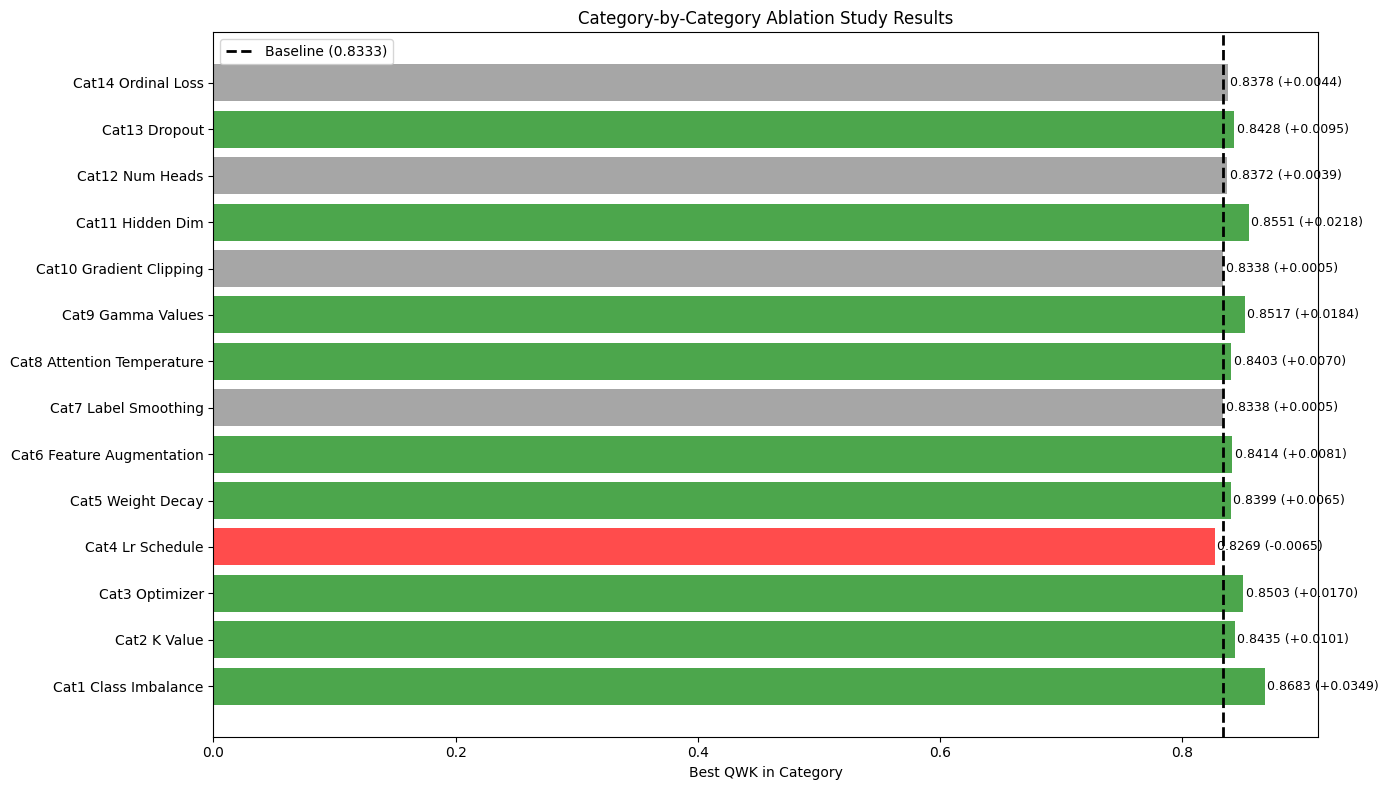

In [17]:
# ============================================================================
# CREATE BEST COMBINATION
# ============================================================================

best_combination, helpful_changes = create_best_combination(best_per_category, all_results)

# Plot category summary
plot_category_summary(all_results, best_per_category)

---
## Section 13: Run 5-Fold Cross-Validation

In [18]:
# ============================================================================
# RUN 5-FOLD CV ON BASELINE
# ============================================================================

print('\n' + '='*70)
print('RUNNING 5-FOLD CV ON BASELINE')
print('='*70)

baseline_cv = run_5fold_cv({}, 'Baseline (no changes)')


RUNNING 5-FOLD CV ON BASELINE

5-FOLD CROSS-VALIDATION: Baseline (no changes)
Total samples: 600

--- Fold 1/5 ---
  Fold 1: QWK=0.8357, Acc=0.5583

--- Fold 2/5 ---
  Fold 2: QWK=0.8811, Acc=0.6667

--- Fold 3/5 ---
  Fold 3: QWK=0.8308, Acc=0.5833

--- Fold 4/5 ---
  Fold 4: QWK=0.8934, Acc=0.6000

--- Fold 5/5 ---
  Fold 5: QWK=0.8739, Acc=0.6667

5-FOLD CV RESULTS: Baseline (no changes)
  QWK:      0.8630 +/- 0.0251
  Accuracy: 0.6150 +/- 0.0442
  Macro F1: 0.6080 +/- 0.0418


In [19]:
# ============================================================================
# RUN 5-FOLD CV ON BEST COMBINATION
# ============================================================================

if best_combination:
    print('\n' + '='*70)
    print('RUNNING 5-FOLD CV ON BEST COMBINATION')
    print('='*70)

    best_cv = run_5fold_cv(best_combination, 'Best Combination')
else:
    print('\nNo improvements found - skipping best combination CV')
    best_cv = baseline_cv


RUNNING 5-FOLD CV ON BEST COMBINATION

5-FOLD CROSS-VALIDATION: Best Combination
Total samples: 600

--- Fold 1/5 ---
  Fold 1: QWK=0.8189, Acc=0.5833

--- Fold 2/5 ---
  Fold 2: QWK=0.8743, Acc=0.6083

--- Fold 3/5 ---
  Fold 3: QWK=0.8582, Acc=0.6000

--- Fold 4/5 ---
  Fold 4: QWK=0.8801, Acc=0.6417

--- Fold 5/5 ---
  Fold 5: QWK=0.8812, Acc=0.6417

5-FOLD CV RESULTS: Best Combination
  QWK:      0.8625 +/- 0.0233
  Accuracy: 0.6150 +/- 0.0232
  Macro F1: 0.6047 +/- 0.0400


---
## Section 14: Final Results

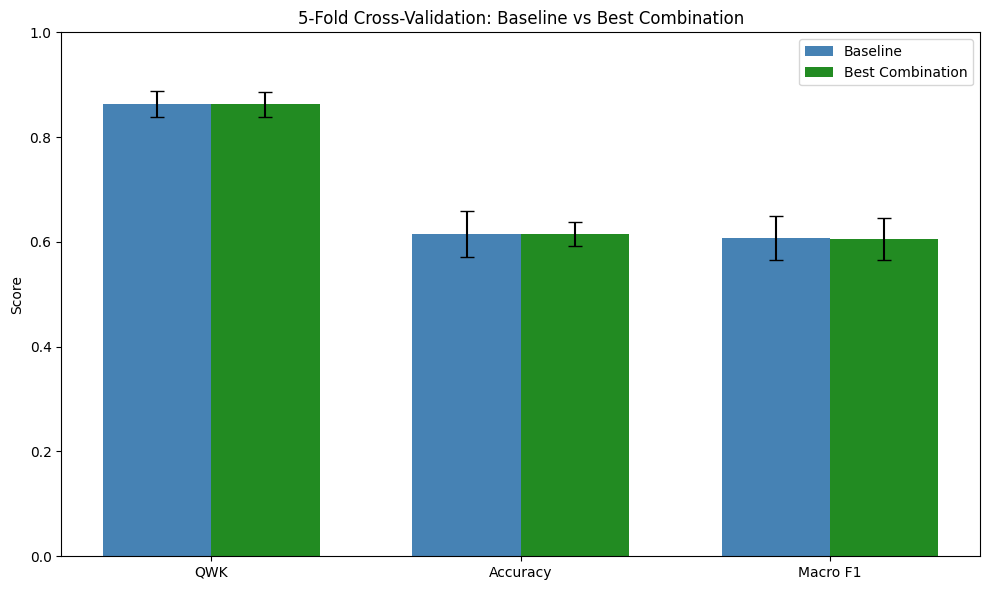


FINAL COMPARISON (5-Fold Cross-Validation)

Model                     QWK                  Accuracy             Macro F1            
--------------------------------------------------------------------------------
Baseline                  0.8630 +/- 0.0251      0.6150 +/- 0.0442      0.6080 +/- 0.0418
Best Combination          0.8625 +/- 0.0233      0.6150 +/- 0.0232      0.6047 +/- 0.0400
--------------------------------------------------------------------------------
Improvement: QWK -0.0004, Accuracy +0.0000

Results saved to: /content/drive/MyDrive/CLAM_TR_Results/v5_category_ablation/


In [20]:
# ============================================================================
# FINAL COMPARISON
# ============================================================================

# Plot CV comparison
if best_combination:
    plot_cv_comparison(baseline_cv, best_cv)

# Print final comparison
print('\n' + '='*80)
print('FINAL COMPARISON (5-Fold Cross-Validation)')
print('='*80)
print(f'\n{"Model":<25} {"QWK":<20} {"Accuracy":<20} {"Macro F1":<20}')
print('-'*80)
print(f'{"Baseline":<25} {baseline_cv["mean_qwk"]:.4f} +/- {baseline_cv["std_qwk"]:.4f}      {baseline_cv["mean_accuracy"]:.4f} +/- {baseline_cv["std_accuracy"]:.4f}      {baseline_cv["mean_f1"]:.4f} +/- {baseline_cv["std_f1"]:.4f}')

if best_combination:
    print(f'{"Best Combination":<25} {best_cv["mean_qwk"]:.4f} +/- {best_cv["std_qwk"]:.4f}      {best_cv["mean_accuracy"]:.4f} +/- {best_cv["std_accuracy"]:.4f}      {best_cv["mean_f1"]:.4f} +/- {best_cv["std_f1"]:.4f}')

    # Improvement
    qwk_improvement = best_cv['mean_qwk'] - baseline_cv['mean_qwk']
    acc_improvement = best_cv['mean_accuracy'] - baseline_cv['mean_accuracy']

    print('-'*80)
    print(f'Improvement: QWK {qwk_improvement:+.4f}, Accuracy {acc_improvement:+.4f}')

print('='*80)

# Save final results
final_results = {
    'timestamp': datetime.now().isoformat(),
    'categories_tested': len(CATEGORIES),
    'experiments_tested': sum(len(c['experiments']) for c in CATEGORIES.values()),
    'helpful_changes': list(helpful_changes.keys()) if helpful_changes else [],
    'best_combination_config': best_combination,
    'baseline_cv': {
        'mean_qwk': baseline_cv['mean_qwk'],
        'std_qwk': baseline_cv['std_qwk'],
        'mean_accuracy': baseline_cv['mean_accuracy'],
        'std_accuracy': baseline_cv['std_accuracy'],
    },
    'best_combination_cv': {
        'mean_qwk': best_cv['mean_qwk'],
        'std_qwk': best_cv['std_qwk'],
        'mean_accuracy': best_cv['mean_accuracy'],
        'std_accuracy': best_cv['std_accuracy'],
    } if best_combination else None,
}

with open(os.path.join(CONFIG['results_dir'], 'final_results.json'), 'w') as f:
    json.dump(final_results, f, indent=2, default=str)

print(f'\nResults saved to: {CONFIG["results_dir"]}')

In [21]:
# ============================================================================
# CONCLUSION
# ============================================================================

print('\n' + '='*80)
print('CATEGORY-BY-CATEGORY ABLATION STUDY COMPLETE!')
print('='*80)

print(f'''
Summary:
  - Categories tested: {len(CATEGORIES)}
  - Total experiments: {sum(len(c['experiments']) for c in CATEGORIES.values())}
  - Helpful changes: {len(helpful_changes) if helpful_changes else 0}

Files saved:
  - Category results: {CONFIG['results_dir']}/category_results.json
  - Final results: {CONFIG['results_dir']}/final_results.json
  - Visualizations: {CONFIG['results_dir']}/visualizations/
''')

if helpful_changes:
    print('Helpful changes found:')
    for cat_name, config in helpful_changes.items():
        print(f'  - {cat_name}: {config.get("name", "?")}')

print('='*80)


CATEGORY-BY-CATEGORY ABLATION STUDY COMPLETE!

Summary:
  - Categories tested: 14
  - Total experiments: 74
  - Helpful changes: 11

Files saved:
  - Category results: /content/drive/MyDrive/CLAM_TR_Results/v5_category_ablation//category_results.json
  - Final results: /content/drive/MyDrive/CLAM_TR_Results/v5_category_ablation//final_results.json
  - Visualizations: /content/drive/MyDrive/CLAM_TR_Results/v5_category_ablation//visualizations/

Helpful changes found:
  - cat1_class_imbalance: Focal loss (gamma=1)
  - cat2_k_value: K=128 (baseline)
  - cat3_optimizer: AdamW
  - cat5_weight_decay: weight_decay=1e-5 (baseline)
  - cat6_feature_augmentation: No augmentation (baseline)
  - cat8_attention_temperature: Temperature 0.7
  - cat9_gamma_values: Higher [0.88-0.995] (slower decay)
  - cat11_hidden_dim: hidden_dim=512 (baseline)
  - cat12_num_heads: 4 heads
  - cat13_dropout: Dropout 0.15
  - cat14_ordinal_loss: No ordinal (baseline)


---
## Section 15: Category 15 - RetNet Architecture Variations

This section tests **29 different RetNet architecture variations** organized into 7 groups:
- **VA (Original)**: RetNet as described in the paper
- **VB (Simple)**: Lighter versions for smaller datasets
- **VC (Pathology)**: Our pathology-adapted innovations (2D spatial PE, learnable gamma)
- **VD (Deep)**: Stacked retention layers
- **VE (Hybrid)**: Mixed approaches combining CLAM + RetNet
- **VF (Gates)**: Different gating mechanisms (Swish, GLU, GeGLU, Bilinear)
- **VG (Norms)**: Different normalization strategies

In [22]:
# ============================================================================
# CATEGORY 15: RETNET ARCHITECTURE VARIATIONS
# ============================================================================

CATEGORY_15_RETNET = {
    'cat15_retnet_architecture': {
        'description': 'RetNet Architecture Variations (Multiple Versions)',
        'experiments': {

            # ==================================================================
            # BASELINE: Current Implementation (No RetNet enhancements)
            # ==================================================================
            'v0_baseline': {
                'name': 'V0: Baseline (current)',
                'retnet_version': 'none',
            },

            # ==================================================================
            # VERSION A: ORIGINAL RETNET STYLE (From Paper)
            # ==================================================================
            'vA1_original_minimal': {
                'name': 'VA1: Original - Minimal',
                'retnet_version': 'original',
                'use_retention_norm': True,
                'norm_type': 'group',
                'use_retention_residual': True,
            },
            'vA2_original_with_gate': {
                'name': 'VA2: Original - With Gate',
                'retnet_version': 'original',
                'use_retention_norm': True,
                'norm_type': 'group',
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'swish',
            },
            'vA3_original_full': {
                'name': 'VA3: Original - Full',
                'retnet_version': 'original',
                'use_retention_norm': True,
                'norm_type': 'group',
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'swish',
                'use_retention_ffn': True,
                'ffn_expansion': 4,
            },

            # ==================================================================
            # VERSION B: SIMPLIFIED RETNET (Lighter, Faster)
            # ==================================================================
            'vB1_simple_norm_only': {
                'name': 'VB1: Simple - LayerNorm only',
                'retnet_version': 'simple',
                'use_retention_norm': True,
                'norm_type': 'layer',
            },
            'vB2_simple_residual_only': {
                'name': 'VB2: Simple - Residual only',
                'retnet_version': 'simple',
                'use_retention_residual': True,
            },
            'vB3_simple_norm_residual': {
                'name': 'VB3: Simple - Norm + Residual',
                'retnet_version': 'simple',
                'use_retention_norm': True,
                'norm_type': 'layer',
                'use_retention_residual': True,
            },
            'vB4_simple_light_ffn': {
                'name': 'VB4: Simple - Light FFN',
                'retnet_version': 'simple',
                'use_retention_norm': True,
                'norm_type': 'layer',
                'use_retention_residual': True,
                'use_retention_ffn': True,
                'ffn_expansion': 2,
            },

            # ==================================================================
            # VERSION C: PATHOLOGY-ADAPTED RETNET (Our Innovation)
            # ==================================================================
            'vC1_patho_spatial_pe': {
                'name': 'VC1: Pathology - 2D Spatial PE',
                'retnet_version': 'pathology',
                'use_spatial_pe': True,
                'spatial_pe_type': 'sinusoidal',
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vC2_patho_learnable_pe': {
                'name': 'VC2: Pathology - Learnable PE',
                'retnet_version': 'pathology',
                'use_spatial_pe': True,
                'spatial_pe_type': 'learnable',
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vC3_patho_learnable_gamma': {
                'name': 'VC3: Pathology - Learnable Gamma',
                'retnet_version': 'pathology',
                'use_learnable_gamma': True,
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vC4_patho_distance_encoding': {
                'name': 'VC4: Pathology - Distance Enc',
                'retnet_version': 'pathology',
                'use_distance_encoding': True,
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vC5_patho_full': {
                'name': 'VC5: Pathology - Full',
                'retnet_version': 'pathology',
                'use_spatial_pe': True,
                'spatial_pe_type': 'sinusoidal',
                'use_learnable_gamma': True,
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'glu',
            },
            'vC6_patho_complete': {
                'name': 'VC6: Pathology - Complete',
                'retnet_version': 'pathology',
                'use_spatial_pe': True,
                'spatial_pe_type': 'learnable',
                'use_learnable_gamma': True,
                'use_distance_encoding': True,
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_gate': True,
                'use_retention_ffn': True,
                'ffn_expansion': 2,
            },

            # ==================================================================
            # VERSION D: DEEP RETNET (Stacked Layers)
            # ==================================================================
            'vD1_deep_2layers': {
                'name': 'VD1: Deep - 2 Layers',
                'retnet_version': 'deep',
                'num_retention_layers': 2,
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vD2_deep_3layers': {
                'name': 'VD2: Deep - 3 Layers',
                'retnet_version': 'deep',
                'num_retention_layers': 3,
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vD3_deep_2layers_ffn': {
                'name': 'VD3: Deep - 2 Layers + FFN',
                'retnet_version': 'deep',
                'num_retention_layers': 2,
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_ffn': True,
                'ffn_expansion': 2,
            },

            # ==================================================================
            # VERSION E: HYBRID RETNET
            # ==================================================================
            'vE1_hybrid_learned': {
                'name': 'VE1: Hybrid - Learned Fusion',
                'retnet_version': 'hybrid',
                'fusion_type': 'learned',
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vE2_hybrid_parallel': {
                'name': 'VE2: Hybrid - Parallel Fusion',
                'retnet_version': 'hybrid',
                'fusion_type': 'parallel',
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vE3_hybrid_attention_gate': {
                'name': 'VE3: Hybrid - Attention Gate',
                'retnet_version': 'hybrid',
                'use_attention_gate': True,
                'use_retention_norm': True,
                'use_retention_residual': True,
            },
            'vE4_hybrid_best': {
                'name': 'VE4: Hybrid - Best Combo',
                'retnet_version': 'hybrid',
                'fusion_type': 'learned',
                'use_spatial_pe': True,
                'use_learnable_gamma': True,
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'glu',
            },

            # ==================================================================
            # VERSION F: GATE VARIATIONS
            # ==================================================================
            'vF1_gate_swish': {
                'name': 'VF1: Gate - Swish',
                'retnet_version': 'gate_test',
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'swish',
            },
            'vF2_gate_glu': {
                'name': 'VF2: Gate - GLU',
                'retnet_version': 'gate_test',
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'glu',
            },
            'vF3_gate_geglu': {
                'name': 'VF3: Gate - GeGLU',
                'retnet_version': 'gate_test',
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'geglu',
            },
            'vF4_gate_bilinear': {
                'name': 'VF4: Gate - Bilinear',
                'retnet_version': 'gate_test',
                'use_retention_norm': True,
                'use_retention_residual': True,
                'use_retention_gate': True,
                'gate_type': 'bilinear',
            },

            # ==================================================================
            # VERSION G: NORMALIZATION VARIATIONS
            # ==================================================================
            'vG1_norm_layer': {
                'name': 'VG1: Norm - LayerNorm',
                'retnet_version': 'norm_test',
                'use_retention_norm': True,
                'norm_type': 'layer',
                'norm_position': 'post',
                'use_retention_residual': True,
            },
            'vG2_norm_group': {
                'name': 'VG2: Norm - GroupNorm',
                'retnet_version': 'norm_test',
                'use_retention_norm': True,
                'norm_type': 'group',
                'num_groups': 8,
                'norm_position': 'post',
                'use_retention_residual': True,
            },
            'vG3_norm_rms': {
                'name': 'VG3: Norm - RMSNorm',
                'retnet_version': 'norm_test',
                'use_retention_norm': True,
                'norm_type': 'rms',
                'norm_position': 'post',
                'use_retention_residual': True,
            },
            'vG4_norm_pre': {
                'name': 'VG4: Norm - Pre-Norm',
                'retnet_version': 'norm_test',
                'use_retention_norm': True,
                'norm_type': 'layer',
                'norm_position': 'pre',
                'use_retention_residual': True,
            },
        }
    }
}

print(f'Category 15 defined: {len(CATEGORY_15_RETNET["cat15_retnet_architecture"]["experiments"])} experiments')
print('\nExperiment groups:')
print('  V0: Baseline (1)')
print('  VA: Original RetNet (3)')
print('  VB: Simple RetNet (4)')
print('  VC: Pathology-Adapted (6)')
print('  VD: Deep RetNet (3)')
print('  VE: Hybrid RetNet (4)')
print('  VF: Gate Variations (4)')
print('  VG: Norm Variations (4)')

Category 15 defined: 29 experiments

Experiment groups:
  V0: Baseline (1)
  VA: Original RetNet (3)
  VB: Simple RetNet (4)
  VC: Pathology-Adapted (6)
  VD: Deep RetNet (3)
  VE: Hybrid RetNet (4)
  VF: Gate Variations (4)
  VG: Norm Variations (4)


In [23]:
# ============================================================================
# RETNET COMPONENTS - NORMALIZATION, GATES, POSITION ENCODING
# ============================================================================

import math

# ----------------------------------------------------------------------------
# NORMALIZATION LAYERS
# ----------------------------------------------------------------------------

class RMSNorm(nn.Module):
    """Root Mean Square Normalization (from LLaMA)."""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        rms = torch.sqrt(torch.mean(x ** 2, dim=-1, keepdim=True) + self.eps)
        return x / rms * self.weight


def get_norm_layer(norm_type, dim, num_groups=8):
    """Get normalization layer by type."""
    if norm_type == 'layer':
        return nn.LayerNorm(dim)
    elif norm_type == 'group':
        return nn.GroupNorm(num_groups, dim)
    elif norm_type == 'rms':
        return RMSNorm(dim)
    elif norm_type == 'batch':
        return nn.BatchNorm1d(dim)
    else:
        return nn.Identity()


# ----------------------------------------------------------------------------
# GATE LAYERS
# ----------------------------------------------------------------------------

class SwishGate(nn.Module):
    """Swish Gate: x * sigmoid(Wx)"""
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * torch.sigmoid(self.proj(x))


class GLUGate(nn.Module):
    """GLU Gate: x * sigmoid(Wx + b)"""
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * torch.sigmoid(self.proj(x))


class GeGLUGate(nn.Module):
    """GeGLU Gate: x * gelu(Wx)"""
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * F.gelu(self.proj(x))


class BilinearGate(nn.Module):
    """Bilinear Gate: W1(x) * W2(x)"""
    def __init__(self, dim):
        super().__init__()
        self.proj1 = nn.Linear(dim, dim)
        self.proj2 = nn.Linear(dim, dim)

    def forward(self, x):
        return self.proj1(x) * torch.sigmoid(self.proj2(x))


def get_gate_layer(gate_type, dim):
    """Get gate layer by type."""
    if gate_type == 'swish':
        return SwishGate(dim)
    elif gate_type == 'glu':
        return GLUGate(dim)
    elif gate_type == 'geglu':
        return GeGLUGate(dim)
    elif gate_type == 'bilinear':
        return BilinearGate(dim)
    else:
        return nn.Identity()


# ----------------------------------------------------------------------------
# POSITION ENCODING LAYERS
# ----------------------------------------------------------------------------

class SinusoidalPositionEncoding2D(nn.Module):
    """2D Sinusoidal Position Encoding for pathology patches."""
    def __init__(self, dim, max_size=10000):
        super().__init__()
        self.dim = dim

        pe = torch.zeros(max_size, dim // 2)
        position = torch.arange(0, max_size, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, dim // 2, 2).float() * (-math.log(10000.0) / (dim // 2)))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

        self.combine = nn.Linear(dim, dim)

    def forward(self, coords, patch_size=256):
        x_idx = (coords[:, 0] / patch_size).long().clamp(0, self.pe.size(0) - 1)
        y_idx = (coords[:, 1] / patch_size).long().clamp(0, self.pe.size(0) - 1)

        pe_x = self.pe[x_idx]
        pe_y = self.pe[y_idx]

        return self.combine(torch.cat([pe_x, pe_y], dim=-1))


class LearnablePositionEncoding2D(nn.Module):
    """Learnable 2D Position Encoding."""
    def __init__(self, dim, max_size=100):
        super().__init__()
        self.x_embedding = nn.Embedding(max_size, dim // 2)
        self.y_embedding = nn.Embedding(max_size, dim // 2)
        self.combine = nn.Linear(dim, dim)

    def forward(self, coords, patch_size=256):
        x_idx = (coords[:, 0] / patch_size).long().clamp(0, self.x_embedding.num_embeddings - 1)
        y_idx = (coords[:, 1] / patch_size).long().clamp(0, self.y_embedding.num_embeddings - 1)

        pe_x = self.x_embedding(x_idx)
        pe_y = self.y_embedding(y_idx)

        return self.combine(torch.cat([pe_x, pe_y], dim=-1))


class DistanceEncoding(nn.Module):
    """Encode pairwise distances as features."""
    def __init__(self, dim, num_bins=32):
        super().__init__()
        self.num_bins = num_bins
        self.distance_embedding = nn.Embedding(num_bins, dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, coords, patch_size=256):
        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)

        max_dist = distances.max() + 1e-6
        bins = (distances / max_dist * (self.num_bins - 1)).long().clamp(0, self.num_bins - 1)

        dist_emb = self.distance_embedding(bins)
        return self.proj(dist_emb.mean(dim=1))


# ----------------------------------------------------------------------------
# FFN BLOCK
# ----------------------------------------------------------------------------

class FFNBlock(nn.Module):
    """Feed-Forward Network block."""
    def __init__(self, dim, expansion=4, dropout=0.1):
        super().__init__()
        hidden_dim = dim * expansion
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return x + self.net(self.norm(x))


print('RetNet components defined: RMSNorm, Gates, Position Encodings, FFN')

RetNet components defined: RMSNorm, Gates, Position Encodings, FFN


In [24]:
# ============================================================================
# FLEXIBLE RETNET MODULE & CLAM_TR_RETNET MODEL
# ============================================================================

class RetNetSpatialHead(nn.Module):
    """Single attention head with spatial decay (for RetNet)."""
    def __init__(self, dim, gamma, num_heads, learnable_gamma=False):
        super().__init__()
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5

        if learnable_gamma:
            self.gamma = nn.Parameter(torch.tensor(gamma))
        else:
            self.register_buffer('gamma', torch.tensor(gamma))

        self.W_Q = nn.Linear(dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(dim, self.head_dim, bias=False)

    def forward(self, x, coords):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)

        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)
        normalized = distances / (distances.max() + 1e-6)

        gamma = torch.clamp(self.gamma, 0.5, 0.999)
        D = gamma ** normalized

        scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale
        scores = scores * D
        attn = F.softmax(scores, dim=-1)

        return torch.matmul(attn, V)


class MultiHeadRetention(nn.Module):
    """Multi-head spatial retention."""
    def __init__(self, dim, num_heads=8, gamma_values=None, learnable_gamma=False):
        super().__init__()
        if gamma_values is None:
            gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]

        if len(gamma_values) != num_heads:
            gamma_values = np.linspace(gamma_values[0], gamma_values[-1], num_heads).tolist()

        self.heads = nn.ModuleList([
            RetNetSpatialHead(dim, gamma_values[i], num_heads, learnable_gamma)
            for i in range(num_heads)
        ])
        self.output_proj = nn.Linear(dim, dim)

    def forward(self, x, coords):
        head_outputs = [head(x, coords) for head in self.heads]
        concat = torch.cat(head_outputs, dim=-1)
        return self.output_proj(concat)


class RetentionLayer(nn.Module):
    """Single retention layer with configurable components."""
    def __init__(self, dim, num_heads=8, gamma_values=None,
                 use_norm=True, norm_type='layer', norm_position='post', num_groups=8,
                 use_residual=True,
                 use_gate=False, gate_type='swish',
                 use_ffn=False, ffn_expansion=4,
                 learnable_gamma=False,
                 dropout=0.1):
        super().__init__()

        self.use_norm = use_norm
        self.norm_position = norm_position
        self.use_residual = use_residual
        self.use_gate = use_gate
        self.use_ffn = use_ffn

        self.retention = MultiHeadRetention(dim, num_heads, gamma_values, learnable_gamma)

        if use_norm:
            self.norm = get_norm_layer(norm_type, dim, num_groups)

        if use_gate:
            self.gate = get_gate_layer(gate_type, dim)

        if use_ffn:
            self.ffn = FFNBlock(dim, ffn_expansion, dropout)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, coords):
        identity = x

        if self.use_norm and self.norm_position == 'pre':
            x = self.norm(x)

        out = self.retention(x, coords)
        out = self.dropout(out)

        if self.use_norm and self.norm_position == 'post':
            out = self.norm(out)

        if self.use_residual:
            out = out + identity

        if self.use_gate:
            out = self.gate(out)

        if self.use_ffn:
            out = self.ffn(out)

        return out


class FlexibleRetNet(nn.Module):
    """Flexible RetNet supporting all variations."""
    def __init__(self, dim, num_heads=8, gamma_values=None, patch_size=256,
                 use_norm=True, norm_type='layer', norm_position='post', num_groups=8,
                 use_residual=True,
                 use_gate=False, gate_type='swish',
                 use_ffn=False, ffn_expansion=4,
                 use_spatial_pe=False, spatial_pe_type='sinusoidal',
                 use_learnable_gamma=False,
                 use_distance_encoding=False,
                 num_retention_layers=1,
                 dropout=0.1):
        super().__init__()

        self.use_spatial_pe = use_spatial_pe
        self.use_distance_encoding = use_distance_encoding
        self.patch_size = patch_size

        if use_spatial_pe:
            if spatial_pe_type == 'sinusoidal':
                self.spatial_pe = SinusoidalPositionEncoding2D(dim)
            else:
                self.spatial_pe = LearnablePositionEncoding2D(dim)

        if use_distance_encoding:
            self.distance_enc = DistanceEncoding(dim)

        self.layers = nn.ModuleList([
            RetentionLayer(
                dim=dim, num_heads=num_heads, gamma_values=gamma_values,
                use_norm=use_norm, norm_type=norm_type, norm_position=norm_position,
                num_groups=num_groups, use_residual=use_residual,
                use_gate=use_gate, gate_type=gate_type,
                use_ffn=use_ffn, ffn_expansion=ffn_expansion,
                learnable_gamma=use_learnable_gamma, dropout=dropout
            )
            for _ in range(num_retention_layers)
        ])

    def forward(self, x, coords):
        if self.use_spatial_pe:
            x = x + self.spatial_pe(coords, self.patch_size)

        if self.use_distance_encoding:
            x = x + self.distance_enc(coords, self.patch_size)

        for layer in self.layers:
            x = layer(x, coords)

        return x


class CLAM_TR_RetNet(nn.Module):
    """CLAM-TR with flexible RetNet variations."""
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6,
                 dropout=0.25, K=128, num_heads=8, gamma_values=None, patch_size=256,
                 attention_temperature=1.0, retnet_config=None):
        super().__init__()
        self.K = K
        self.attention_temperature = attention_temperature

        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.attention_a = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Sigmoid(),
            nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim // 2, 1)

        self.use_retnet = retnet_config is not None and retnet_config.get('retnet_version', 'none') != 'none'

        if self.use_retnet:
            self.retnet = FlexibleRetNet(
                dim=hidden_dim, num_heads=num_heads, gamma_values=gamma_values,
                patch_size=patch_size,
                use_norm=retnet_config.get('use_retention_norm', False),
                norm_type=retnet_config.get('norm_type', 'layer'),
                norm_position=retnet_config.get('norm_position', 'post'),
                num_groups=retnet_config.get('num_groups', 8),
                use_residual=retnet_config.get('use_retention_residual', False),
                use_gate=retnet_config.get('use_retention_gate', False),
                gate_type=retnet_config.get('gate_type', 'swish'),
                use_ffn=retnet_config.get('use_retention_ffn', False),
                ffn_expansion=retnet_config.get('ffn_expansion', 4),
                use_spatial_pe=retnet_config.get('use_spatial_pe', False),
                spatial_pe_type=retnet_config.get('spatial_pe_type', 'sinusoidal'),
                use_learnable_gamma=retnet_config.get('use_learnable_gamma', False),
                use_distance_encoding=retnet_config.get('use_distance_encoding', False),
                num_retention_layers=retnet_config.get('num_retention_layers', 1),
                dropout=dropout
            )

            self.fusion_type = retnet_config.get('fusion_type', 'add')
            if self.fusion_type == 'learned':
                self.fusion_gate = nn.Sequential(
                    nn.Linear(hidden_dim * 2, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, 2),
                    nn.Softmax(dim=-1)
                )
            elif self.fusion_type == 'parallel':
                self.fusion_proj = nn.Linear(hidden_dim * 2, hidden_dim)

        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords):
        h = self.feature_transform(x)

        a = self.attention_a(h)
        b = self.attention_b(h)
        A = self.attention_c(a * b).squeeze(-1) / self.attention_temperature
        A_softmax = F.softmax(A, dim=0)

        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices

        h_topk = h[topk_indices]
        coords_topk = coords[topk_indices]
        A_topk = A_softmax[topk_indices]

        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)

        if self.use_retnet:
            retention_out = self.retnet(h_topk, coords_topk)
            M_retention = torch.mean(retention_out, dim=0)

            if self.fusion_type == 'add':
                M = M_clam + M_retention
            elif self.fusion_type == 'learned':
                concat = torch.cat([M_clam, M_retention], dim=-1)
                weights = self.fusion_gate(concat.unsqueeze(0)).squeeze(0)
                M = weights[0] * M_clam + weights[1] * M_retention
            elif self.fusion_type == 'parallel':
                M = self.fusion_proj(torch.cat([M_clam, M_retention], dim=-1))
            else:
                M = M_clam + M_retention
        else:
            M = M_clam

        return self.classifier(M)


print('CLAM_TR_RetNet model defined!')

CLAM_TR_RetNet model defined!


In [25]:
# ============================================================================
# TRAINING FUNCTION FOR RETNET EXPERIMENTS
# ============================================================================

def train_retnet_experiment(exp_config, train_loader, val_loader, device):
    """Train experiment with RetNet support."""

    hidden_dim = exp_config.get('hidden_dim', CONFIG['hidden_dim'])
    num_heads = exp_config.get('num_heads', CONFIG['num_heads'])
    gamma_values = exp_config.get('gamma_values', CONFIG['gamma_values'])
    K = exp_config.get('K', CONFIG['K'])
    dropout = exp_config.get('dropout', CONFIG['dropout'])
    attention_temp = exp_config.get('attention_temperature', 1.0)

    model = CLAM_TR_RetNet(
        input_dim=CONFIG['feature_dim'],
        hidden_dim=hidden_dim,
        n_classes=CONFIG['n_classes'],
        dropout=dropout,
        K=K,
        num_heads=num_heads,
        gamma_values=gamma_values,
        patch_size=CONFIG['patch_size'],
        attention_temperature=attention_temp,
        retnet_config=exp_config
    ).to(device)

    num_params = sum(p.numel() for p in model.parameters())

    criterion = FlexibleLoss(
        n_classes=CONFIG['n_classes'],
        smoothing=exp_config.get('label_smoothing', CONFIG['label_smoothing']),
        use_focal=exp_config.get('use_focal_loss', False),
        focal_gamma=exp_config.get('focal_gamma', 2.0),
        use_ordinal=exp_config.get('use_ordinal_loss', False),
        ordinal_weight=exp_config.get('ordinal_weight', 0.3),
        class_weights=exp_config.get('class_weights') if exp_config.get('use_class_weights', False) else None
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=exp_config.get('lr', CONFIG['lr']),
        weight_decay=exp_config.get('weight_decay', CONFIG['weight_decay'])
    )

    epochs = exp_config.get('epochs', CONFIG['epochs'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    early_stopping = EarlyStopping(patience=CONFIG['early_stopping_patience'])
    best_qwk = -1
    best_model_state = None
    best_epoch = 0

    for epoch in range(epochs):
        model.train()
        for features, coords, label, _ in train_loader:
            features, coords = features.to(device), coords.to(device)
            label = torch.tensor(label).to(device)

            optimizer.zero_grad()
            logits = model(features, coords)
            loss = criterion(logits, label)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        scheduler.step()

        model.eval()
        preds, labels = [], []
        with torch.no_grad():
            for features, coords, label, _ in val_loader:
                features, coords = features.to(device), coords.to(device)
                logits = model(features, coords)
                preds.append(logits.argmax().cpu().item())
                labels.append(label)

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if early_stopping(qwk):
            break

    model.load_state_dict(best_model_state)
    model.eval()

    preds, labels = [], []
    with torch.no_grad():
        for features, coords, label, _ in val_loader:
            features, coords = features.to(device), coords.to(device)
            logits = model(features, coords)
            preds.append(logits.argmax().cpu().item())
            labels.append(label)

    del model
    del criterion
    torch.cuda.empty_cache()

    return {
        'qwk': cohen_kappa_score(labels, preds, weights='quadratic'),
        'accuracy': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
        'best_epoch': best_epoch,
        'params': num_params,
    }


print('train_retnet_experiment function defined!')

train_retnet_experiment function defined!


In [26]:
# ============================================================================
# RUN CATEGORY 15: RETNET ARCHITECTURE VARIATIONS
# ============================================================================

def run_category_15():
    """Run all RetNet architecture experiments."""

    cat_data = CATEGORY_15_RETNET['cat15_retnet_architecture']

    print(f'\n{"="*70}')
    print(f'CATEGORY 15: RETNET ARCHITECTURE VARIATIONS')
    print(f'Description: {cat_data["description"]}')
    print(f'Total experiments: {len(cat_data["experiments"])}')
    print(f'{"="*70}')

    # Load data
    subset_csv = os.path.join(CONFIG['original_checkpoints'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['features_dir'], 'uni')

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    train_df, val_df = train_test_split(
        df, test_size=0.2, stratify=df['isup_grade'], random_state=CONFIG['seed']
    )

    train_ds = PANDAFeatureDataset(train_df['image_id'].tolist(), train_df['isup_grade'].tolist(), features_dir)
    val_ds = PANDAFeatureDataset(val_df['image_id'].tolist(), val_df['isup_grade'].tolist(), features_dir)

    train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

    print(f'Train: {len(train_df)}, Val: {len(val_df)}')

    # Check for existing results
    results_file = os.path.join(CONFIG['results_dir'], 'retnet_results.json')
    if os.path.exists(results_file):
        with open(results_file, 'r') as f:
            results = json.load(f)
        print(f'Loaded {len(results)} existing results')
    else:
        results = {}

    for exp_name, exp_config in cat_data['experiments'].items():
        # Skip if already done
        if exp_name in results:
            print(f'\n  Skipping: {exp_config["name"]} (already done)')
            continue

        print(f'\n  Running: {exp_config["name"]}...', end=' ', flush=True)

        try:
            metrics = train_retnet_experiment(exp_config, train_loader, val_loader, DEVICE)
            results[exp_name] = {
                'name': exp_config['name'],
                'config': {k: str(v) if isinstance(v, (list, dict)) else v for k, v in exp_config.items()},
                'metrics': metrics
            }
            print(f'QWK={metrics["qwk"]:.4f}, Acc={metrics["accuracy"]:.4f}, Params={metrics["params"]:,}')
        except Exception as e:
            print(f'ERROR: {e}')
            results[exp_name] = {
                'name': exp_config['name'],
                'metrics': {'qwk': 0, 'accuracy': 0, 'error': str(e)}
            }

        torch.cuda.empty_cache()

        # Save after each experiment
        with open(results_file, 'w') as f:
            json.dump(results, f, indent=2, default=str)

    # Print summary
    print(f'\n{"="*90}')
    print(f'CATEGORY 15 RESULTS: RETNET ARCHITECTURE VARIATIONS')
    print(f'{"="*90}')
    print(f'{"Experiment":<40} {"QWK":>10} {"Accuracy":>10} {"Params":>15}')
    print(f'{"-"*90}')

    baseline_qwk = results.get('v0_baseline', {}).get('metrics', {}).get('qwk', 0.83)

    for exp_name, data in sorted(results.items(), key=lambda x: x[1].get('metrics', {}).get('qwk', 0), reverse=True):
        m = data.get('metrics', {})
        qwk = m.get('qwk', 0)
        diff = qwk - baseline_qwk
        marker = '+' if diff > 0.005 else ('~' if diff > -0.005 else '-')
        print(f'{data["name"]:<40} {qwk:>10.4f} {m.get("accuracy", 0):>10.4f} {m.get("params", 0):>15,} {marker}')

    print(f'{"="*90}')

    # Find best
    valid_results = {k: v for k, v in results.items() if 'error' not in v.get('metrics', {})}
    if valid_results:
        best = max(valid_results.items(), key=lambda x: x[1]['metrics']['qwk'])
        print(f'\nBEST: {best[1]["name"]} (QWK={best[1]["metrics"]["qwk"]:.4f})')

        improvement = best[1]['metrics']['qwk'] - baseline_qwk
        print(f'Improvement over baseline: {improvement:+.4f}')

    return results


print('run_category_15 function defined!')

run_category_15 function defined!


In [27]:
# ============================================================================
# RUN CATEGORY 15
# ============================================================================
# This will run 29 RetNet architecture experiments
# Results are saved after each experiment - can resume if interrupted
# Estimated time: ~20 hours
# ============================================================================

retnet_results = run_category_15()


CATEGORY 15: RETNET ARCHITECTURE VARIATIONS
Description: RetNet Architecture Variations (Multiple Versions)
Total experiments: 29
Train: 480, Val: 120

  Running: V0: Baseline (current)... QWK=0.7801, Acc=0.5667, Params=790,791

  Running: VA1: Original - Minimal... QWK=0.8520, Acc=0.6333, Params=1,840,903

  Running: VA2: Original - With Gate... QWK=0.8414, Acc=0.6000, Params=2,103,559

  Running: VA3: Original - Full... QWK=0.8679, Acc=0.6083, Params=4,204,295

  Running: VB1: Simple - LayerNorm only... QWK=0.8574, Acc=0.6250, Params=1,840,903

  Running: VB2: Simple - Residual only... QWK=0.8034, Acc=0.5333, Params=1,839,879

  Running: VB3: Simple - Norm + Residual... QWK=0.7849, Acc=0.5750, Params=1,840,903

  Running: VB4: Simple - Light FFN... QWK=0.8195, Acc=0.6083, Params=2,892,039

  Running: VC1: Pathology - 2D Spatial PE... QWK=0.7730, Acc=0.5500, Params=2,103,559

  Running: VC2: Pathology - Learnable PE... QWK=0.8175, Acc=0.5667, Params=2,154,759

  Running: VC3: Patholo